# 04 · Feed-forward networks and Mixture of Experts

**What you will learn**
- The FFN is where ~2/3 of parameters (and most factual knowledge) live; SwiGLU vs GELU
- MoE: decouple parameters from compute with a router that picks top-k experts per token
- The load-balancing problem: auxiliary loss (Switch/Mixtral) vs bias-balanced routing (DeepSeek-V3)
- Fine-grained + shared experts (DeepSeekMoE)
- Evaluation: total vs active parameters, expert utilization, quality vs a dense model at equal *active* compute

**Source:** `llm_edu_suite/layers.py` (`SwiGLU`, `MoE`, `AuxFreeRouter`), `llm_edu_suite/model.py`.

## Background: the feed-forward block

A transformer block has two sub-layers with very different jobs. **Attention** moves information *between* positions: each token reads from the others. The **feed-forward network (FFN)** then transforms each position *on its own*, with the same weights at every position:

$$\text{FFN}(x) = W_2\,\sigma(W_1 x), \qquad W_1 \in \mathbb{R}^{d_{ff}\times C},\; W_2 \in \mathbb{R}^{C\times d_{ff}},\; d_{ff} = 4C$$

That is the original 2017 design (with ReLU as $\sigma$). Count the parameters per layer: attention with full multi-head projections has $Q, K, V, O$, about $4C^2$; the FFN has $2 \cdot C \cdot 4C = 8C^2$. So roughly **two thirds of the non-embedding parameters sit in the FFN**, and since a forward pass costs about 2 FLOPs per parameter per token, the FFN also dominates the compute at short and medium context lengths. With grouped-query attention (notebook 02) the K and V projections shrink and the FFN share grows further.

### What the FFN computes

A useful way to read the FFN is as a **key-value memory** (Geva et al., 2021). Each row $k_i$ of $W_1$ is a "key" that is matched against the token's hidden state, and the corresponding column $v_i$ of $W_2$ is a "value" that gets added to the residual stream in proportion to the match:

$$\text{FFN}(x) = \sum_{i=1}^{d_{ff}} \sigma(k_i^\top x)\; v_i$$

With $d_{ff}$ in the tens of thousands per layer, this is a very large table of learned patterns and the vectors they write. Follow-up work (Meng et al., 2022, ROME) showed that some factual associations can be located in mid-layer MLPs and even edited there. Treat "knowledge lives in the FFN" as a good working approximation rather than a law: other studies find facts spread across many layers and components, and the question is still actively researched.

### From ReLU to GELU to SwiGLU

The activation $\sigma$ has changed over the years, and the current standard adds a **gate**:

| activation | formula | used by | notes |
|---|---|---|---|
| ReLU | $\max(0, z)$ | original Transformer (2017) | simple; units that stay negative get no gradient ("dead" units) |
| GELU | $z\,\Phi(z)$ | BERT, GPT-2, GPT-3 | smooth version of ReLU; small negative values pass |
| SwiGLU | $\text{SiLU}(W_{gate}x) \odot W_{up}x$ | PaLM, Llama 1-3, Mistral, Qwen, DeepSeek | gated; three matrices instead of two |

Here $\text{SiLU}(z) = z\,\sigma(z)$ (also called Swish) and $\odot$ is element-wise multiplication. A **gated linear unit** (Dauphin et al., 2017) computes two linear projections of the same input and lets one modulate the other. The result is a *multiplicative* interaction: each hidden unit is the product of two different linear features of $x$, which a single linear map followed by a pointwise nonlinearity cannot express directly. Gates also give a smoother gradient path, because the "up" branch is linear and never saturates.

Shazeer (2020) compared many GLU variants at equal parameter count and found that SwiGLU and GEGLU gave lower perplexity than ReLU and GELU FFNs. He was refreshingly honest about the theory: the paper says the authors "offer no explanation" for why these architectures work and attribute their success "to divine benevolence". The evidence for SwiGLU is empirical and consistent across labs, which is why it became the default; a fully satisfying theoretical account does not exist.

**Matching the parameter budget.** SwiGLU has three matrices of size $C \times d_{ff}$ instead of two. To keep the FFN at $8C^2$ parameters you need $3 C d_{ff} = 8C^2$, so $d_{ff} = \tfrac{8}{3}C$. Implementations then round $d_{ff}$ up to a hardware-friendly multiple (256 or 1024). Llama 3 also multiplies by a configurable `ffn_dim_multiplier` (1.3 for the 8B model) before rounding, which is how a model with $C = 4096$ ends up with $d_{ff} = 14336 = 3.5\,C$: its FFN is deliberately *larger* than the parameter-matched $\tfrac{8}{3}C$.

## Background: sparse mixture of experts

### The problem: parameters cost compute

Scaling laws (notebook 05) say that larger models trained on more data reach lower loss. In a dense model every parameter is used for every token, so doubling the parameters doubles the FLOPs per token, for training and for inference. **Conditional computation** breaks that link: keep many parameters, but let each token use only a few of them.

A **mixture-of-experts (MoE) layer** replaces the single FFN with $E$ expert FFNs and a small **router** that chooses $k \ll E$ of them per token:

```
          x (one token)
          |
     router: s = W_r x  ->  scores for E experts
          |
     pick top-k (e.g. 2 of 8)
        /     \
  Expert_3   Expert_7     (the other 6 experts do no work for this token)
        \     /
   y = g_3 * E_3(x) + g_7 * E_7(x)
```

Formally, with router weights $W_r \in \mathbb{R}^{E \times C}$:

$$g = \text{softmax}(W_r x), \qquad \mathcal{T} = \text{TopK}(g, k), \qquad y = \sum_{e \in \mathcal{T}} \frac{g_e}{\sum_{j \in \mathcal{T}} g_j}\, \text{FFN}_e(x)$$

The gate values $g_e$ multiply the expert outputs for a reason: the top-k selection itself is not differentiable, so the **only gradient the router receives flows through the gate values** of the selected experts. If an expert's output helps reduce the loss, its gate is pushed up for similar inputs. DeepSeek-V3 uses a sigmoid per expert instead of a softmax over all experts and normalizes over the selected ones; the principle is the same.

### Cost model: three different budgets

| quantity | dense FFN | MoE with $E$ experts, top-$k$ |
|---|---|---|
| parameters in memory | $P$ | about $E \cdot P_e$ (plus router) |
| FLOPs per token | $\propto P$ | $\propto k \cdot P_e$ ("active" parameters) |
| communication | none extra | all-to-all dispatch and combine when experts live on different GPUs |

This is the whole trade: MoE buys **capacity** (total parameters, which store knowledge) at a fixed **compute** per token, and pays in **memory** and **communication**. Mixtral 8x7B, for example, needs memory for all of its ~47B parameters even though each token only uses ~13B of them. That makes MoE attractive for large training runs and high-throughput serving on many GPUs, and much less attractive on a single consumer GPU, where memory is the scarce resource.

### A short history

| year | work | contribution |
|---|---|---|
| 1991 | Jacobs, Jordan, Nowlan, Hinton, *Adaptive Mixtures of Local Experts* | the original idea: a gating network blends specialist networks |
| 2017 | Shazeer et al., *Outrageously Large Neural Networks: The Sparsely-Gated Mixture-of-Experts Layer* | sparse top-k gating with noise, thousands of experts inside LSTMs, an auxiliary balancing loss |
| 2020 | Lepikhin et al., *GShard* | MoE in transformers, top-2 routing, expert capacity, sharding across devices |
| 2021 | Fedus, Zoph, Shazeer, *Switch Transformers* | top-1 routing, a simplified load-balancing loss, trillion-parameter scale |
| 2022 | Zoph et al., *ST-MoE* | router z-loss for stability, guidance on fine-tuning MoE models |
| 2024 | Jiang et al., *Mixtral of Experts* | strong open-weight MoE (8 experts, top-2) |
| 2024 | Dai et al., *DeepSeekMoE* | fine-grained experts plus always-on shared experts |
| 2024 | Wang et al., *Auxiliary-Loss-Free Load Balancing Strategy for Mixture-of-Experts*; DeepSeek-AI, *DeepSeek-V3 Technical Report* | bias-based balancing without an auxiliary loss, at 671B scale |

Today many of the largest open-weight models are MoE (the DeepSeek-V3/R1 family, Qwen3's MoE variants, Llama 4, Mixtral), and several closed frontier models are widely believed to be as well, though their labs rarely confirm architecture details.

### Why it works, and what experts actually learn

The intuition is that different tokens need different "knowledge lookups", so a model with many FFNs can store more patterns while each token only consults the few that are relevant. It is tempting to imagine a "math expert" and a "biology expert", but that is mostly not what happens. The Mixtral paper reports no obvious topic-based specialization; routing correlates more with syntax and token type (for example, indentation tokens in code, or particular word pieces). Experts specialize, but along dimensions the optimizer finds useful, not along human categories.

### Load balancing: the central difficulty

Routing has a **rich-get-richer** failure. An expert that is chosen slightly more often early in training receives more gradient updates, becomes better, and is chosen even more. Left alone, the router collapses onto a few experts. That wastes the parameters of the others and, with experts spread across GPUs, turns the busiest expert into a bottleneck: implementations with a fixed **capacity** per expert (a buffer of size $\text{capacity factor} \times kT/E$ tokens for a batch of $T$ tokens) simply **drop** the overflow tokens, which then skip the FFN through the residual connection.

**Auxiliary loss (Shazeer 2017, simplified in Switch).** Add a term to the training loss:

$$\mathcal{L}_{aux} = \alpha\, E \sum_{e=1}^{E} f_e\, P_e, \qquad f_e = \frac{\#\text{tokens routed to } e}{T}, \qquad P_e = \frac{1}{T}\sum_{t=1}^{T} g_e(x_t)$$

$f_e$ is a hard count and has no gradient; $P_e$ is the mean router probability and does. The product is smallest when both are uniform, and its gradient pushes probability away from experts that are already over-used (large $f_e$). Switch used $\alpha = 0.01$. The trade-off is unavoidable: the balancing gradient competes with the language-modeling gradient, so a large $\alpha$ hurts quality and a small one does not balance. ST-MoE added a **router z-loss**, $\frac{1}{T}\sum_t \big(\log \sum_e e^{s_{t,e}}\big)^2$, which keeps router logits small and avoids numerical instability.

**Auxiliary-loss-free balancing (Wang et al. 2024, DeepSeek-V3).** Keep a bias $b_e$ per expert that is used **only to choose** the experts, not to weight their outputs:

$$\mathcal{T} = \text{TopK}\big(s_e + b_e,\; k\big), \qquad y = \sum_{e \in \mathcal{T}} \tilde g_e\, \text{FFN}_e(x), \qquad b_e \leftarrow b_e - \gamma\, \text{sign}\big(\text{load}_e - \overline{\text{load}}\big)$$

The bias is updated after each step from the observed load, with no gradient at all. It behaves like a price in a market, or the integral term of a controller: over-used experts become "more expensive" and lose marginal tokens until the load evens out. Because the gate values $\tilde g_e$ still come from the unbiased scores, the language-modeling gradient is not mixed with a balancing objective. Two honest caveats: DeepSeek-V3 still adds a *very small* sequence-wise balance loss as a safety net, and the update speed $\gamma$ must be small (0.001 in DeepSeek-V3) or the loads oscillate, which the experiment below shows.

### Fine-grained and shared experts

DeepSeekMoE made two changes that most recent MoE models adopted:
- **Fine-grained experts**: split each expert into $m$ smaller ones and route each token to $m \cdot k$ of them. The compute is the same, but the number of possible expert combinations grows enormously (choosing 2 of 8 gives 28 combinations; choosing 8 of 64 gives about 4.4 billion), so each token can get a more specific mix.
- **Shared experts**: one or a few experts that every token uses. They absorb common knowledge (frequent words, basic syntax) that every routed expert would otherwise have to re-learn, so the routed experts can specialize.

### Routing schemes compared

| scheme | how tokens and experts are matched | strengths | weaknesses |
|---|---|---|---|
| token choice, top-$k$ + aux loss (GShard, Switch, Mixtral) | each token picks its $k$ best experts | simple, causal-friendly | needs a balancing loss that competes with the LM loss; token dropping at capacity |
| expert choice (Zhou et al., 2022) | each expert picks its top tokens in the batch | perfect balance by construction | a token's routing depends on other tokens in the batch, which is awkward for autoregressive decoding |
| token choice + bias (DeepSeek-V3) | top-$k$ on biased scores, gates from unbiased scores | balance without gradient interference | an extra hyperparameter $\gamma$; balance holds on average, not per batch |

### Common failure modes

- **Routing collapse** and dead experts (watch per-expert load, as this notebook does).
- **Instability**: router logits grow and loss spikes; the z-loss and computing the router in fp32 are the usual remedies.
- **Token dropping** when capacity is too small; "dropless" implementations such as MegaBlocks (Gale et al., 2022) use block-sparse kernels to avoid it.
- **Fine-tuning**: ST-MoE reported that sparse models can overfit more easily than dense ones on small downstream tasks.
- **Serving**: all experts must be resident in memory, and per-token routing makes batches uneven, so throughput depends on the traffic mix.

### Key papers

- Vaswani et al. (2017), *Attention Is All You Need*.
- Dauphin, Fan, Auli, Grangier (2017), *Language Modeling with Gated Convolutional Networks*.
- Shazeer (2020), *GLU Variants Improve Transformer*.
- Geva, Schuster, Berant, Levy (2021), *Transformer Feed-Forward Layers Are Key-Value Memories*.
- Shazeer et al. (2017), *Outrageously Large Neural Networks: The Sparsely-Gated Mixture-of-Experts Layer*.
- Fedus, Zoph, Shazeer (2021), *Switch Transformers: Scaling to Trillion Parameter Models with Simple and Efficient Sparsity*.
- Zoph et al. (2022), *ST-MoE: Designing Stable and Transferable Sparse Expert Models*.
- Dai et al. (2024), *DeepSeekMoE: Towards Ultimate Expert Specialization in Mixture-of-Experts Language Models*.
- Wang et al. (2024), *Auxiliary-Loss-Free Load Balancing Strategy for Mixture-of-Experts*.
- DeepSeek-AI (2024), *DeepSeek-V3 Technical Report*.

In [1]:
import os, sys, math, time, tempfile
ROOT = os.path.abspath(".")
while not os.path.isdir(os.path.join(ROOT, "llm_edu_suite")) and os.path.dirname(ROOT) != ROOT:
    ROOT = os.path.dirname(ROOT)                    # notebooks live in notebooks/<topic>/, so climb up to the repo root
sys.path.insert(0, ROOT)                            # so that `import llm_edu_suite` works from the notebook
import numpy as np
import matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F
from llm_edu_suite.utils import seed_everything, get_device, count_params, human, show_mask
seed_everything(0)
device = get_device()
print("torch", torch.__version__, "| device", device)

torch 2.14.1+cu130 | device cuda


## SwiGLU
$$\text{FFN}(x) = W_{down}\big(\text{SiLU}(W_{gate}x) \odot W_{up}x\big)$$
A gated unit: one branch decides *how much* passes, the other *what*. Three matrices instead of two, so `d_ff ≈ 8/3·C` keeps the parameter count of a 4·C two-matrix FFN. Real models then round and sometimes enlarge it: Llama 3 8B uses 4096 → 14336, which is 3.5·C because of an extra multiplier.

**What the next cell checks.** A GELU FFN with $d_{ff} = 4C$ has $8C^2$ weights; a SwiGLU FFN with $d_{ff} \approx \tfrac{8}{3}C$ has $3 \cdot \tfrac{8}{3} C^2 = 8C^2$. The two counts should be almost equal, differing only by the rounding of $d_{ff}$ to a multiple of 8. The second line reproduces the Llama 3 rule, which applies the 1.3 multiplier and rounds to 1024, so the 8B model's FFN is about 30 % wider than the parameter-matched size (see the Background section).

The comparison is "same parameters, different function". The gain from SwiGLU in the literature is a modest but consistent perplexity improvement at equal size; at this toy scale we only check the bookkeeping, not the quality.

In [2]:
from llm_edu_suite.layers import SwiGLU, swiglu_hidden_dim
C = 128
class FFN_GELU(nn.Module):
    def __init__(self, C, d_ff):
        super().__init__(); self.w1 = nn.Linear(C, d_ff, bias=False); self.w2 = nn.Linear(d_ff, C, bias=False)
    def forward(self, x): return self.w2(F.gelu(self.w1(x)))

d_ff = swiglu_hidden_dim(C, multiple_of=8)
print(f"GELU FFN d_ff={4*C}: {count_params(FFN_GELU(C, 4*C)):,} params | SwiGLU d_ff={d_ff}: {count_params(SwiGLU(C, d_ff)):,} params")
print("Llama-3-8B rule:", swiglu_hidden_dim(4096, multiple_of=1024, ffn_dim_multiplier=1.3))

GELU FFN d_ff=512: 131,072 params | SwiGLU d_ff=344: 132,096 params
Llama-3-8B rule: 14336


## MoE: router + experts

```
probs   = softmax(W_router x)                 # one score per expert
top_k   = best k experts, weights renormalized
output  = Σ_{e∈top_k} w_e · Expert_e(x)       # only k experts run
```
Mixtral 8x7B: 47B total / 13B active. DeepSeek-V3: 671B / 37B (256 experts, k=8, 1 shared).

**Load balancing.** Without it the router collapses onto a few experts. Two fixes:
- **Auxiliary loss** $\mathcal{L}_{aux} = E\sum_e f_e P_e$ (fraction of tokens × mean router prob per expert), minimal when uniform; added with coefficient ≈ 0.01.
- **Aux-free (DeepSeek-V3):** a per-expert bias added to the scores *only for selection*, nudged up for under-used experts and down for over-used ones after each batch. The language objective is left almost untouched (DeepSeek-V3 still keeps a very small sequence-level balance loss as a safety net).

**How to read the next cell.** The layer below has 8 routed experts, top-2 routing and 1 shared expert.

- **Aux loss scale.** In this implementation $f_e$ counts routed *slots*, so $\sum_e f_e = k$ instead of 1, and with uniform routing $E \sum_e f_e P_e = E \cdot E \cdot \tfrac{k}{E} \cdot \tfrac{1}{E} = k$. Any value above $k$ means some experts get both more tokens and more probability than their share. Papers differ in whether they normalize $f_e$ by $k$, so always check the convention before comparing loss values across codebases.
- **Total vs active parameters.** Per token, the shared expert, the router and 2 of the 8 routed experts run; the other 6 routed experts are memory, not compute. That is why the cell subtracts 6 experts to get the active count. The ratio total/active is the "free" capacity MoE buys, paid for in memory.
- **Load.** The ideal per-expert load is $k/E$. A freshly initialized router on random inputs is roughly balanced by symmetry; imbalance appears during training, when the rich-get-richer dynamics kick in.

In [3]:
from llm_edu_suite.layers import MoE, AuxFreeRouter

moe = MoE(C, d_ff=128, n_experts=8, top_k=2, n_shared=1, routing="softmax")
x = torch.randn(4, 32, C)
y, aux = moe(x)
# f_e counts routed *slots* per token, so sum_e f_e = top_k and a perfectly balanced router scores exactly top_k (2.0 here).
print("out", tuple(y.shape), f"| aux loss {aux.item():.3f} (perfectly uniform = top_k = {moe.k:.1f}; larger = imbalanced)")
print("slots per expert / tokens:", [round(v, 2) for v in moe.last_load.tolist()], f"(ideal top_k/E = {2/8:.2f} each)")
n_total = count_params(moe); n_expert = count_params(moe.experts[0]); n_active = n_total - 6 * n_expert
print(f"params total {n_total:,} | active per token {n_active:,} | ratio {n_total / n_active:.2f}x")

out (4, 32, 128) | aux loss 2.024 (perfectly uniform = top_k = 2.0; larger = imbalanced)
slots per expert / tokens: [0.25, 0.23, 0.27, 0.27, 0.17, 0.25, 0.21, 0.34] (ideal top_k/E = 0.25 each)
params total 443,392 | active per token 148,480 | ratio 2.99x


### Aux-free balancing in action
We force a badly imbalanced router (experts 0 and 1 receive almost every token) and watch the per-expert bias equalize the load — **without any gradient** on the router weights. After each batch the bias of over-used experts goes down by `bias_lr` and the bias of under-used ones goes up (`bias -= lr * sign(load - mean)`).

The update size matters: the scores are sigmoids in [0, 1], so a large `bias_lr` (e.g. 0.1) overshoots and the load *oscillates* between two bad states; DeepSeek-V3 uses a small value (0.001 at scale). We plot the imbalance ratio `max load / mean load` (1.0 = perfect).

**Why a sign update converges, and why it can oscillate.** The rule $b_e \leftarrow b_e - \gamma\,\text{sign}(\text{load}_e - \overline{\text{load}})$ is a feedback controller with a fixed step. Selection is a hard top-$k$, so the load of an expert changes in jumps whenever its biased score crosses the score of a competitor. If $\gamma$ is small compared with the typical gap between scores, each step moves only a few marginal tokens and the loads settle into a small band around the mean. If $\gamma$ is large, one step moves a big block of tokens at once: the over-used expert becomes under-used, the sign flips, and the system bounces between two states. This is the same stability argument as for a learning rate that is too large. Note also that the bias never touches the router weights, so it can only *redistribute* tokens near a decision boundary; it does not teach the router new features.

bias_lr=0.1  : step 0 load [1020, 988, 2, 5, 24, 7, 2, 0]  ->  step 79 load [8, 431, 358, 128, 320, 78, 343, 382]  (imbalance 3.98x -> 1.68x)
bias_lr=0.01 : step 0 load [1024, 959, 14, 4, 11, 11, 17, 8]  ->  step 79 load [294, 214, 259, 263, 270, 239, 231, 278]  (imbalance 4.00x -> 1.15x)


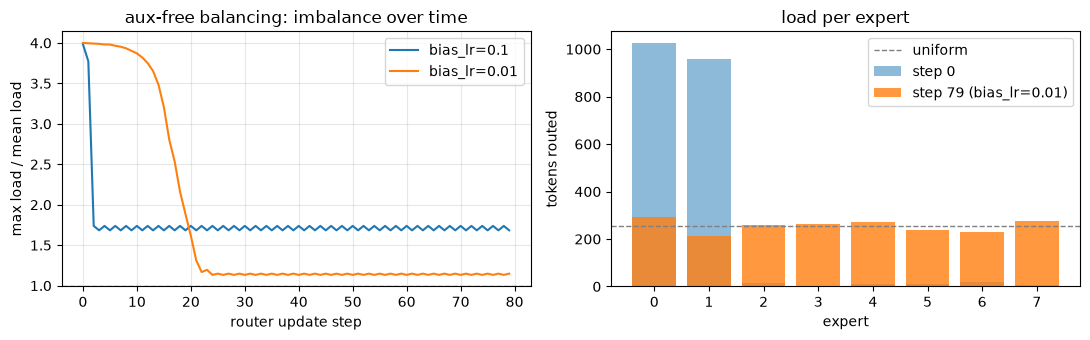

In [4]:
torch.manual_seed(0)
xf = torch.randn(1024, C) + 0.5                       # the inputs all share a common direction...
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
for bias_lr in (0.1, 0.01):
    router = AuxFreeRouter(C, n_experts=8, top_k=2, bias_lr=bias_lr).train()
    with torch.no_grad():
        router.weight.weight[0] += 0.05; router.weight.weight[1] += 0.03   # ...and we nudge experts 0 and 1 to point along it
    imbalance, loads = [], []
    for step in range(80):
        idx, w, _ = router(xf)
        load = F.one_hot(idx, 8).sum((0, 1)).float()
        imbalance.append((load.max() / load.mean()).item()); loads.append(load)
    ax[0].plot(imbalance, label=f"bias_lr={bias_lr}")
    print(f"bias_lr={bias_lr:<5}: step 0 load {loads[0].int().tolist()}  ->  step 79 load {loads[-1].int().tolist()}"
          f"  (imbalance {imbalance[0]:.2f}x -> {imbalance[-1]:.2f}x)")
ax[0].axhline(1, color="gray", ls="--", lw=1); ax[0].set_xlabel("router update step"); ax[0].set_ylabel("max load / mean load")
ax[0].set_title("aux-free balancing: imbalance over time"); ax[0].legend(); ax[0].grid(alpha=.3)
ax[1].bar(range(8), loads[0].tolist(), alpha=.5, label="step 0"); ax[1].bar(range(8), loads[-1].tolist(), alpha=.8, label="step 79 (bias_lr=0.01)")
ax[1].axhline(1024 * 2 / 8, color="gray", ls="--", lw=1, label="uniform"); ax[1].set_xlabel("expert"); ax[1].set_ylabel("tokens routed")
ax[1].set_title("load per expert"); ax[1].legend(); plt.tight_layout(); plt.show()

## Evaluation: MoE vs dense at equal *active* compute

The fair comparison is not "same total parameters" but "same FLOPs per token". We train (a) a dense model, (b) a MoE with the same active parameters but 4× total, (c) the same MoE with aux-free routing, for the same steps, and compare validation perplexity and expert utilization. On a toy corpus the MoE advantage is small or absent — MoE pays off with large data and compute; the notebook shows **how to measure**, not that MoE always wins.

**Choosing the comparison axis.** There are three honest ways to compare an MoE with a dense model, and they answer different questions:

| held equal | question it answers | usual outcome at scale |
|---|---|---|
| active parameters (FLOPs per token) | "for the same training and inference compute, which is better?" | MoE wins, because it has more total capacity |
| total parameters (memory) | "for the same GPU memory, which is better?" | dense wins, because every parameter works on every token |
| wall-clock time on given hardware | "what should I deploy here?" | depends on kernels, batch size and expert parallelism |

We use the first axis. Two reasons the MoE advantage may not show here: the corpus is small and simple, so the dense model is not capacity-limited (extra parameters have nothing to store), and with only 300 steps each expert sees roughly half the tokens a dense FFN would, so it is trained less. Published MoE gains come from regimes with far more data than parameters can memorize.

In [5]:
from llm_edu_suite.model import ModelConfig, TransformerLM
from llm_edu_suite.data import synthetic_structured_corpus, train_val_split
from llm_edu_suite.training import TrainConfig, train_lm
from llm_edu_suite.evaluation import perplexity

data = synthetic_structured_corpus(n_tokens=150_000, vocab=512, n_words=120)
train_data, val_data = train_val_split(data)
tcfg = TrainConfig(steps=300, batch_size=32, block_size=64, max_lr=3e-3, warmup=30, eval_every=300, log=False)

runs = {
    "dense":          ModelConfig(vocab_size=512, d_model=128, n_layers=4, n_heads=8, n_kv_heads=2, d_ff=256),
    "MoE 4x top-2":   ModelConfig(vocab_size=512, d_model=128, n_layers=4, n_heads=8, n_kv_heads=2, d_ff=128, moe=True, n_experts=4, top_k=2),
    "MoE aux-free":   ModelConfig(vocab_size=512, d_model=128, n_layers=4, n_heads=8, n_kv_heads=2, d_ff=128, moe=True, n_experts=4, top_k=2, moe_routing="auxfree"),
}
for name, cfg in runs.items():
    seed_everything(0)
    model = TransformerLM(cfg)
    res = train_lm(model, train_data, val_data, tcfg, device)
    ppl = perplexity(model, val_data, block_size=64, n_batches=20, device=device)
    loads = [[round(v, 2) for v in b.ffn.last_load.tolist()] for b in model.blocks if isinstance(b.ffn, MoE)]
    print(f"{name:14s} total {human(model.num_params()):>7}  active {human(model.num_active_params()):>7}  val ppl {ppl:7.2f}  {res.wall_time:4.1f}s")
    if loads:
        print(f"{'':14s} expert load (last batch), layer 0: {loads[0]}")

dense          total 623.74K  active 623.74K  val ppl    3.24   7.2s


MoE 4x top-2   total   1.02M  active 625.79K  val ppl    3.31  16.4s
               expert load (last batch), layer 0: [0.49, 0.53, 0.5, 0.48]


MoE aux-free   total   1.02M  active 625.79K  val ppl    3.24  16.4s
               expert load (last batch), layer 0: [0.51, 0.53, 0.54, 0.42]


**Takeaways**
- Watch the *expert load* row: values near `[0.5, 0.5, 0.5, 0.5]` (k/E = 2/4) mean balanced routing; a dead expert shows as `0.0`.
- MoE's wall time is higher here because the expert loop is Python; grouped GEMM kernels remove that overhead in practice.
- Use MoE when compute-bound at scale with lots of data and expert-parallel infrastructure; otherwise dense. For fine-tuning, dense is far simpler.

**Next:** `05_pretraining.ipynb` — the full training pipeline end to end.